In [1]:
import torch

In [2]:
print(torch.__version__)

2.5.1+cu121


In [3]:
print(torch.cuda.is_available())

True


In [4]:
device="cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [5]:
torch.cuda.get_device_name(0)

'NVIDIA GeForce RTX 4060'

In [6]:
from torchvision import datasets,transforms

In [7]:
train_transform=transforms.Compose([
    transforms.RandomResizedCrop(224,scale=(0.7,1.0)),
    transforms.RandomAffine(degrees=20,translate=(0.1,0.1),shear=10),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.3,0.3,0.3,0.1),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
    ])

In [8]:
test_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

In [9]:
train_dataset=datasets.Food101(
    root="data",
    split="train",
    download=True,
    transform=train_transform
)

In [10]:
test_dataset = datasets.Food101(
    root="data",
    split="test",
    download=True,
    transform=test_transform
)

In [11]:
print(len(train_dataset))
print(len(test_dataset))

75750
25250


In [12]:
from torch.utils.data import DataLoader

In [13]:
train_dataloader=DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=4,
    pin_memory=True
    )

In [14]:
test_dataloader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=4,
    pin_memory=True
)

In [15]:
print(len(train_dataloader))

2368


In [16]:
images,labels=next(iter(train_dataloader))

In [17]:
print(images.shape)
print(labels.shape)

torch.Size([32, 3, 224, 224])
torch.Size([32])


In [18]:
class_names=train_dataset.classes

print(class_names)

['apple_pie', 'baby_back_ribs', 'baklava', 'beef_carpaccio', 'beef_tartare', 'beet_salad', 'beignets', 'bibimbap', 'bread_pudding', 'breakfast_burrito', 'bruschetta', 'caesar_salad', 'cannoli', 'caprese_salad', 'carrot_cake', 'ceviche', 'cheese_plate', 'cheesecake', 'chicken_curry', 'chicken_quesadilla', 'chicken_wings', 'chocolate_cake', 'chocolate_mousse', 'churros', 'clam_chowder', 'club_sandwich', 'crab_cakes', 'creme_brulee', 'croque_madame', 'cup_cakes', 'deviled_eggs', 'donuts', 'dumplings', 'edamame', 'eggs_benedict', 'escargots', 'falafel', 'filet_mignon', 'fish_and_chips', 'foie_gras', 'french_fries', 'french_onion_soup', 'french_toast', 'fried_calamari', 'fried_rice', 'frozen_yogurt', 'garlic_bread', 'gnocchi', 'greek_salad', 'grilled_cheese_sandwich', 'grilled_salmon', 'guacamole', 'gyoza', 'hamburger', 'hot_and_sour_soup', 'hot_dog', 'huevos_rancheros', 'hummus', 'ice_cream', 'lasagna', 'lobster_bisque', 'lobster_roll_sandwich', 'macaroni_and_cheese', 'macarons', 'miso_sou

In [19]:
import matplotlib.pyplot as plt
import numpy as np

In [20]:
image=images[0]
label=labels[0]

In [21]:
image=image.permute(1,2,0)

In [22]:
image=image.numpy()

In [23]:
mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image = image * std + mean

In [24]:
image = np.clip(image, 0, 1)

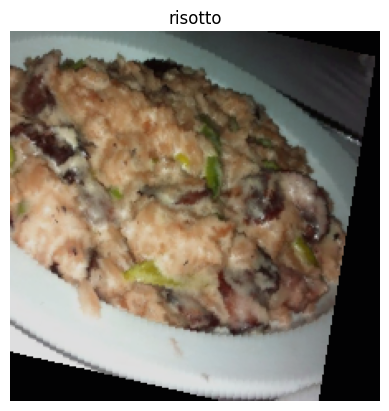

In [25]:
plt.imshow(image)
plt.title(class_names[label])
plt.axis("off")

plt.show()

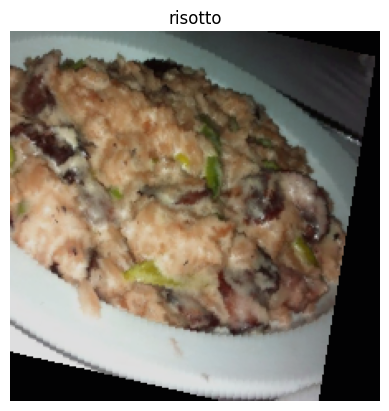

In [26]:
plt.imshow(image)
plt.title(class_names[label])
plt.axis("off")

plt.show()

In [27]:
from torchvision import models

In [28]:
import torch.nn as nn

In [29]:
class FoodCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1=nn.Conv2d(
            in_channels=3,
            out_channels=64,
            kernel_size=3,
            padding=1
        )
        self.pool=nn.MaxPool2d(kernel_size=2,stride=2)
        self.relu=nn.ReLU()
        self.conv2 = nn.Conv2d(
            in_channels=64,
            out_channels=128,
            kernel_size=3,
            padding=1
        )
        self.conv3=nn.Conv2d(
            in_channels=128,
            out_channels=256,
            kernel_size=3,
            padding=1
        )
        self.conv4=nn.Conv2d(
            in_channels=256,
            out_channels=512,
            kernel_size=3,
            padding=1
        )
        self.conv5=nn.Conv2d(
            in_channels=512,
            out_channels=512,
            kernel_size=3,
            padding=1
        )
        self.bn1=nn.BatchNorm2d(64)
        self.bn2=nn.BatchNorm2d(128)
        self.bn3=nn.BatchNorm2d(256)
        self.bn4=nn.BatchNorm2d(512)
        self.bn5=nn.BatchNorm2d(512)

        self.global_pool=nn.AdaptiveAvgPool2d((1,1))

        self.classifier = nn.Sequential(
            nn.Linear(512, 1024),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(1024, 101)
        )
        

    def forward(self,x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = self.pool(self.relu(self.bn4(self.conv4(x))))
        x = self.pool(self.relu(self.bn5(self.conv5(x))))
        
        x = self.global_pool(x)
        x = torch.flatten(x, start_dim=1)
        x = self.classifier(x)
        return x

        

In [30]:
model=FoodCNN().to(device)

In [31]:
print(model)

FoodCNN(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (relu): ReLU()
  (conv2): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv4): Conv2d(256, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv5): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn4): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (bn5): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (global_pool): AdaptiveAvgPool2d(output_size=(1

In [32]:
dummy_input = torch.randn(32, 3, 224, 224).to(device)
output = model(dummy_input)
print("Çıktı Boyutu:", output.shape)

Çıktı Boyutu: torch.Size([32, 101])


In [35]:
loss_fn=nn.CrossEntropyLoss(label_smoothing=0.1)
optimizer=torch.optim.Adam(model.parameters(),lr=0.001)
EPOCHS=50
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,T_max=EPOCHS)


In [36]:


for epoch in range(EPOCHS):
    model.train()
    train_loss=0
    correct=0
    total=0

    for images,labels in train_dataloader:
        images=images.to(device)
        labels=labels.to(device)

        optimizer.zero_grad()
        
        outputs=model(images)

        loss=loss_fn(outputs,labels)

        loss.backward()
        optimizer.step()

        preds = outputs.argmax(dim=1)
        
        correct += (preds == labels).sum().item()
        total += labels.size(0)

        train_loss += loss.item()

    train_acc = correct / total
    train_loss = train_loss / len(train_dataloader)

    model.eval()

    test_loss=0
    correct=0
    total=0

    with torch.no_grad():
        for images,labels in test_dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = loss_fn(outputs, labels)

            test_loss += loss.item()

            preds = outputs.argmax(dim=1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    test_acc = correct / total
    test_loss = test_loss / len(test_dataloader)

    print(f"\nEpoch {epoch+1}")
    print(f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")
    print(f"Val   Loss: {test_loss:.4f} | Val   Acc: {test_acc:.4f}")

    scheduler.step()


Epoch 1
Train Loss: 4.4823 | Train Acc: 0.0298
Val   Loss: 4.3280 | Val   Acc: 0.0499

Epoch 2
Train Loss: 4.3159 | Train Acc: 0.0560
Val   Loss: 4.0966 | Val   Acc: 0.0923

Epoch 3
Train Loss: 4.1543 | Train Acc: 0.0833
Val   Loss: 3.8364 | Val   Acc: 0.1436

Epoch 4
Train Loss: 4.0353 | Train Acc: 0.1048
Val   Loss: 3.7570 | Val   Acc: 0.1554

Epoch 5
Train Loss: 3.9250 | Train Acc: 0.1291
Val   Loss: 3.6523 | Val   Acc: 0.1887

Epoch 6
Train Loss: 3.8267 | Train Acc: 0.1508
Val   Loss: 3.4447 | Val   Acc: 0.2337

Epoch 7
Train Loss: 3.7274 | Train Acc: 0.1745
Val   Loss: 3.3440 | Val   Acc: 0.2658

Epoch 8
Train Loss: 3.6328 | Train Acc: 0.1963
Val   Loss: 3.2157 | Val   Acc: 0.2909

Epoch 9
Train Loss: 3.5427 | Train Acc: 0.2226
Val   Loss: 3.0311 | Val   Acc: 0.3474

Epoch 10
Train Loss: 3.4533 | Train Acc: 0.2441
Val   Loss: 3.0155 | Val   Acc: 0.3527

Epoch 11
Train Loss: 3.3649 | Train Acc: 0.2639
Val   Loss: 2.8620 | Val   Acc: 0.4084

Epoch 12
Train Loss: 3.2831 | Train Acc:

In [37]:
from pathlib import Path

In [39]:
MODEL_PATH=Path("model")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME="Food101_CNN_Classification_Model.pth"
MODEL_SAVE_PATH=MODEL_PATH / MODEL_NAME
print(MODEL_SAVE_PATH)

torch.save(obj=model.state_dict(),f=MODEL_SAVE_PATH)

model\Food101_CNN_Classification_Model.pth


In [49]:
def make_predictions(model: nn.Module, data: list, device=device):
    """
    data: [img_tensor, img_tensor, ...]
    her tensor shape -> [C, H, W]

    return:
    [N, num_classes] probability tensor
    """

    pred_probs = []

    model.eval()

    with torch.inference_mode():
        for sample in data:

            # [C, H, W] -> [1, C, H, W]
            sample = sample.unsqueeze(0).to(device)

            # prediction
            outputs = model(sample)

            # logits -> probabilities
            probs = torch.softmax(outputs, dim=1)

            # remove batch dimension
            pred_probs.append(probs.squeeze(0).cpu())

    # [N, num_classes]
    return torch.stack(pred_probs)

In [50]:
import random
import matplotlib.pyplot as plt

def show_random_predictions(model, dataset, class_names, device=device, n=9):

    model.eval()

    plt.figure(figsize=(10, 10))

    # random index seç
    indices = random.sample(range(len(dataset)), n)

    with torch.inference_mode():

        for i, idx in enumerate(indices):

            img, true_label = dataset[idx]

            # [C, H, W] -> [1, C, H, W]
            img_input = img.unsqueeze(0).to(device)

            # prediction
            outputs = model(img_input)

            pred_label = outputs.argmax(dim=1).item()

            # visualization için cpu
            img_show = img.permute(1, 2, 0).cpu()

            # normalize geri alma
            mean = torch.tensor([0.485, 0.456, 0.406])
            std = torch.tensor([0.229, 0.224, 0.225])

            img_show = img_show * std + mean
            img_show = img_show.clamp(0, 1)

            # doğru / yanlış kontrol
            correct = pred_label == true_label
            color = "green" if correct else "red"

            plt.subplot(3, 3, i + 1)

            plt.imshow(img_show)

            plt.axis("off")

            plt.title(
                f"Pred: {class_names[pred_label]}\nTrue: {class_names[true_label]}",
                color=color,
                fontsize=9
            )

    plt.tight_layout()

    plt.show()

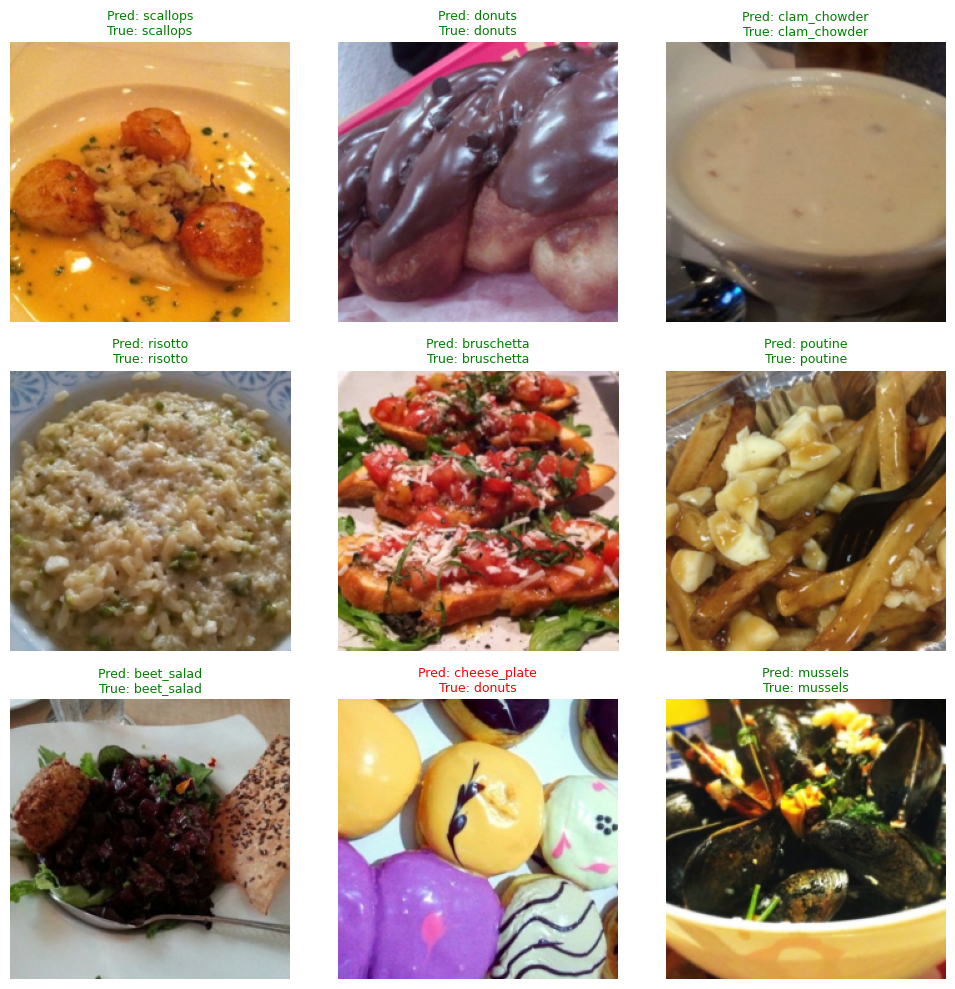

In [57]:
show_random_predictions(model, test_dataset, class_names)